# Lab: Spectrograms, Noise, Clipping and Sampling Rates
**Duration:** about 90 minutes.

## Learning goals
After this lab you can
- explain what a spectrogram shows and how `n_fft`, `hop_length` and the dB scale change the picture,
- decide when a wideband and when a narrowband spectrogram is the right tool for speech,
- explain why linear, log and mel frequency axes exist,
- mix a speech signal with noise recordings and explain what **clipping** is, how it looks and sounds, and how to avoid it,
- explain what the **sampling rate** does to a signal (Nyquist, aliasing) and why speech systems typically use 16 kHz.

## How to work
The code is mostly given, because the lab is about *understanding*, not about programming.
Wherever you see `# TODO`, a short line of code is missing, and it is always the line that carries the key idea.
For every experiment the routine is: **predict → run → look → listen → explain**.
Write down your prediction *before* you run a cell, then compare.

| Part | Topic | Time |
|---|---|---|
| 0 | Setup | 5 min |
| 1 | Waveforms: look and listen | 10 min |
| 2 | From signal to spectrogram, why dB | 15 min |
| 3 | Window size: wideband vs. narrowband | 15 min |
| 4 | Frequency axes: linear, log, mel | 5 min |
| 5 | Adding noise, clipping and how to avoid it | 25 min |
| 6 | Sampling rate, Nyquist and aliasing | 10 min |
| 7 | Putting it together | 5 min |

# Part 0: Setup

In [1]:
# run if needed:
#!pip install numpy matplotlib scipy librosa

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio, display

SR = 16000  # we work at 16 kHz, the usual sampling rate for speech processing

We use three signals:
- `whiskey`: a speech recording (local file),
- `libri1`: a speech recording of a different speaker from the LibriSpeech example set,
- `robin`: a bird, as a non-speech reference.

All three are loaded at 16 kHz and cut to the length of the shortest one, so that they are easy to compare.

In [18]:
whiskey, _ = librosa.load('./ressources/whiskey.wav', sr=SR)
whiskey2 = whiskey * 4
libri1, _ = librosa.load(librosa.example('libri1'), sr=SR, duration=3.2)
robin, _ = librosa.load(librosa.example('robin'), sr=SR)
N = len(robin)  # shortest signal defines the common length
roblib = robin + libri1[:N]
audios = {'whiskey': whiskey[:N], 'libri1': libri1[:N], 'robin': robin, 'whiskey2': whiskey2[:N], 'roblib': roblib}
t = np.arange(N) / SR
print({name: f'{len(y) / SR:.2f} s' for name, y in audios.items()})

{'whiskey': '2.70 s', 'libri1': '2.70 s', 'robin': '2.70 s', 'whiskey2': '2.70 s', 'roblib': '2.70 s'}


Two helper functions, so that the experiments stay short.
Read them once, you do not have to change them.

**Important:** `IPython.display.Audio` normalises the signal to full scale by default (`normalize=True`).
That would hide level differences and also hide clipping.
Our `play` function therefore plays the signal *exactly as it is*, and hard-clips everything outside [-1, 1], as a sound card or a WAV file would do.

In [12]:
def play(y, rate=SR):
    # play y as stored: no normalisation, values outside [-1, 1] are clipped (like a DAC / WAV file)
    return Audio(np.clip(y, -1.0, 1.0), rate=rate, normalize=False)


def plot_spec(y, sr=SR, n_fft=512, hop=None, y_axis='linear', db=True, ref=None,
              ax=None, title='', xlim=None, ylim=None):
    # magnitude spectrogram of y.
    # db=True: dB relative to ref (default: loudest bin of this spectrogram = 0 dB), colour range 0 ... -80 dB.
    # y_axis: 'linear', 'log' or 'mel'.  hop defaults to n_fft // 4.
    ax = ax or plt.gca()
    hop = hop or n_fft // 4
    S = np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop))
    if y_axis == 'mel':
        S = librosa.feature.melspectrogram(S=S, sr=sr, n_fft=n_fft, n_mels=min(80, n_fft // 8))
    if db:
        S = librosa.amplitude_to_db(S, ref=np.max if ref is None else ref, top_db=None)
        style = dict(cmap='magma', vmin=-80, vmax=0)
    else:
        style = dict(cmap='viridis')
    img = librosa.display.specshow(S, sr=sr, hop_length=hop, x_axis='time', y_axis=y_axis, ax=ax, **style)
    plt.colorbar(img, ax=ax, format='%+2.0f dB' if db else None)
    ax.set_title(title)
    if xlim: ax.set_xlim(xlim)
    if ylim: ax.set_ylim(ylim)
    return img

# Part 1: Waveforms, look and listen (10 min)
A digital audio signal is a sequence of numbers: the amplitude, measured `SR` times per second.
In floating point the valid range is **[-1, 1]**.
This is called *full scale*, and we will come back to it in Part 5.

## Task 1.1: Plot the three waveforms and listen to them
All three plots share the same axes, so amplitudes are directly comparable.

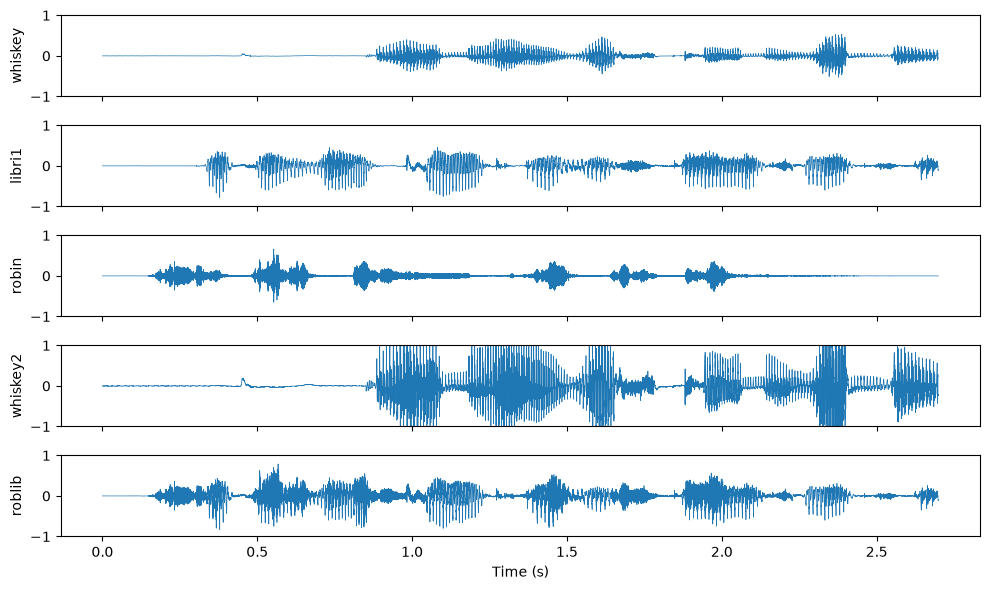

whiskey


libri1


robin


whiskey2


roblib


In [19]:
fig, axes = plt.subplots(5, 1, figsize=(10, 6), sharex=True, sharey=True)
for ax, (name, y) in zip(axes, audios.items()):
    ax.plot(t, y, linewidth=0.5)
    ax.set_ylabel(name)
    ax.set_ylim(-1, 1)
axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()

for name, y in audios.items():
    print(name)
    display(play(y))

## Task 1.2: Measure the level
Two numbers describe how loud a signal is:
- **peak**: the largest absolute sample value (matters for clipping),
- **RMS**: the root mean square, the average "power" of the signal (matters for loudness and for SNR later).

Both are often given in **dBFS** (dB relative to full scale = 1.0): $20\log_{10}(\text{value})$.

In [20]:
for name, y in audios.items():
    peak = np.max(np.abs(y))
    rms = np.sqrt(np.mean(y ** 2))
    print(f'{name:8s} peak = {peak:.2f} ({20 * np.log10(peak):6.1f} dBFS)   rms = {rms:.3f} ({20 * np.log10(rms):6.1f} dBFS)')

whiskey  peak = 0.53 (  -5.4 dBFS)   rms = 0.071 ( -22.9 dBFS)
libri1   peak = 0.78 (  -2.2 dBFS)   rms = 0.120 ( -18.4 dBFS)
robin    peak = 0.66 (  -3.6 dBFS)   rms = 0.068 ( -23.3 dBFS)
whiskey2 peak = 2.14 (   6.6 dBFS)   rms = 0.285 ( -10.9 dBFS)
roblib   peak = 0.83 (  -1.6 dBFS)   rms = 0.138 ( -17.2 dBFS)


**Questions**
1. Which signal is the bird? Could you tell from the waveform alone?
2. What can you read from a waveform (and what not)?
3. How much headroom (distance to full scale) does `whiskey` have? Remember this number for Part 5.

**Solution**
1. `robin` can be recognised by its short, regular, very tonal bursts, but the waveform alone says little. The audio tells it immediately.
2. We can see *when* something happens: pauses, loud and quiet parts, words/syllable rhythm, the amplitude envelope.
   We cannot see *which frequencies* are present, so we cannot tell vowels from fricatives, nor read pitch or formants.
3. `whiskey` has a peak of about 0.53 = about -5.5 dBFS, so there is only about 5.5 dB (a factor of about 1.9) of headroom. Adding anything of similar size will clip.

# Part 2: From signal to spectrogram, and why dB (15 min)
A spectrogram is computed with the **short-time Fourier transform (STFT)**:
1. cut the signal into short, overlapping windows (`n_fft` samples long, moved by `hop_length` samples),
2. multiply each window with a window function (Hann by default),
3. compute the FFT of each window and take the magnitude,
4. put the resulting spectra next to each other: time on the x-axis, frequency on the y-axis, magnitude as colour.

At 16 kHz, `n_fft=512` is a window of 32 ms and `hop_length=128` moves the window by 8 ms.

## Task 2.1: Linear magnitude spectrogram
Plot the spectrogram of all three signals with the **raw magnitude** (no dB conversion).

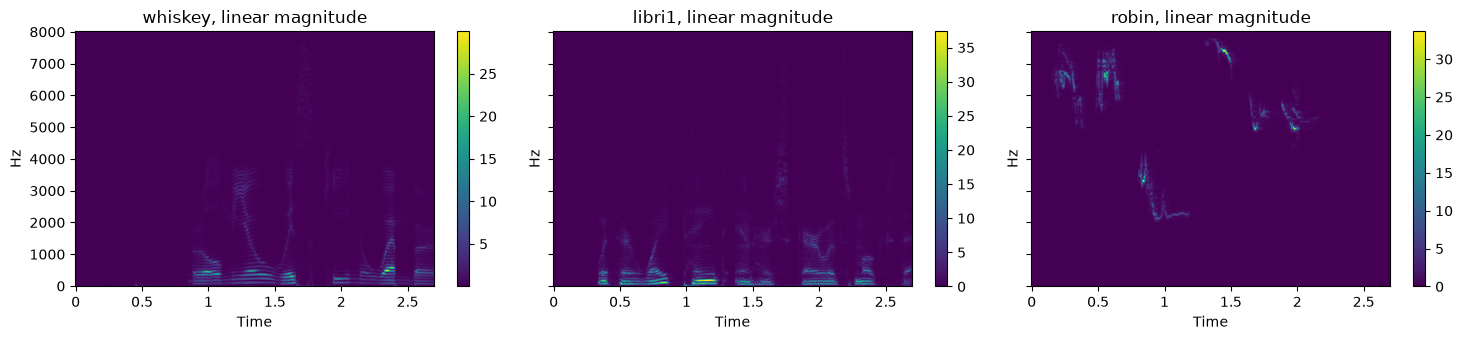

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for ax, (name, y) in zip(axes, audios.items()):
    plot_spec(y, n_fft=512, hop=128, db=False, ax=ax, title=f'{name}, linear magnitude')
plt.tight_layout()
plt.show()

**Solution:** On the linear scale we see only a few bright patches at low frequencies (the strongest harmonics of the vowels, the whistle of the bird).
Everything weaker is practically black: the weaker harmonics, formants at higher frequencies and especially fricatives are not visible.

## Task 2.2: Amplitude to decibel
Convert the magnitude spectrogram to dB and plot it again.

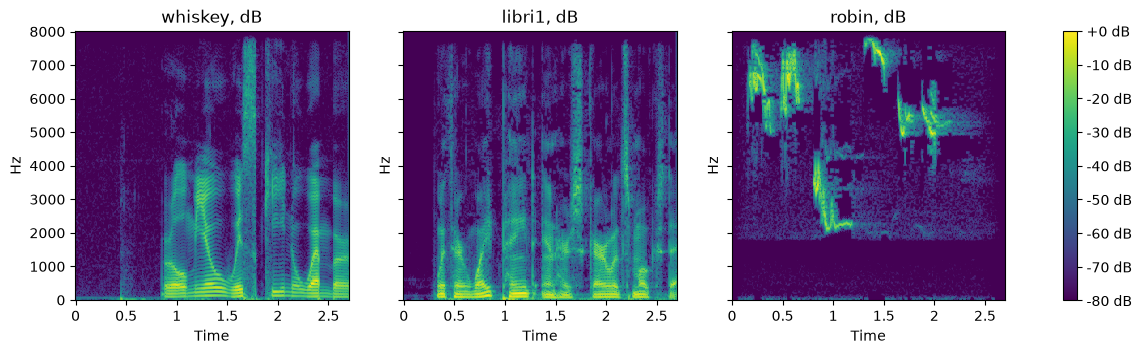

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for ax, (name, y) in zip(axes, audios.items()):
    D = librosa.stft(y, n_fft=512, hop_length=128)
    S = np.abs(D)
    S_db = librosa.amplitude_to_db(S, ref=np.max)
    img = librosa.display.specshow(S_db, sr=SR, hop_length=128, x_axis='time', y_axis='linear', cmap='viridis', vmin=-80, vmax=0, ax=ax)
    # img = librosa.display.specshow(S_db, sr=SR, hop_length=128, x_axis='time', y_axis='linear', cmap='magma', vmin=-80, vmax=0, ax=ax)
    ax.set_title(f'{name}, dB')
plt.colorbar(img, ax=axes, format='%+2.0f dB')
plt.show()

### Why do we use dB?
$$\text{Amplitude in dB} = 20 \cdot \log_{10}\left(\frac{A}{A_\text{ref}}\right)$$

**1. Dynamic range.**
Speech spans several orders of magnitude: a strong vowel harmonic can be 100 to 1000 times larger than the energy of a weak fricative.
On a linear colour scale only the strongest components are visible, as you saw in Task 2.1.
In dB, a ratio of 1000 is "only" 60 dB, which fits on a colour map.

**2. Ratios become differences.**
Multiplying the amplitude by 2 always adds about 6 dB, multiplying by 10 always adds 20 dB.
This is convenient to talk about "how much louder" or "how much quieter".

**3. Closer to perception.**
Human loudness perception is roughly logarithmic, not linear (the exact relation also depends on frequency and level).

**4. Caution: dB reveals noise, it does not remove it.**
Because the quiet parts become visible, the noise floor becomes visible too.
We will use exactly this in Part 5.

**5. dB is always relative to a reference.**
With `ref=np.max` the loudest bin of *each* spectrogram is 0 dB, so absolute level differences between two plots are hidden.
When we want to compare two signals, we need a **common reference**.

## Task 2.3: Get a feeling for dB
Fill in the amplitude factors for the following dB values *before* you run the cell.

In [ ]:
for db in [6, 20, 40, 60, -6, -20, -40, -60]:
    factor = 10 ** (db / 20)
    print(f'{db:+4d} dB  ->  amplitude x {factor:.4g}')

**Questions**
1. A fricative is 40 dB quieter than the vowel next to it. By which factor is its amplitude smaller? What colour does it get on the *linear* colour scale of Task 2.1?
2. Compare the dB spectrograms with what you hear. Find: (a) a voiced sound with harmonics (horizontal stripes), (b) a noise-like sound with energy at high frequencies, (c) a pause. What does the bird look like?

**Solution**
1. -40 dB = factor 0.01. On a linear scale from 0 to the maximum, this is 1 % of the colour range, i.e. practically black.
2. (a) Voiced sounds (vowels) show regularly spaced horizontal stripes: the harmonics of the fundamental frequency, with the formants as broader bright regions.
   (b) Fricatives like /s/ or /sh/ look like a vertical band of "fog" without harmonic structure, with energy mostly above 3-4 kHz.
   (c) Pauses are dark (the noise floor of the recording).
   The bird is a thin, bright line that sweeps through frequency (a nearly pure tone), without the dense harmonic structure of speech.

# Part 3: Window size, wideband vs. narrowband (15 min)
The window length is a trade-off, and you cannot escape it:

| | short window (small `n_fft`) | long window (large `n_fft`) |
|---|---|---|
| time resolution | good | poor |
| frequency resolution | poor | good |
| name for speech | **wideband** | **narrowband** |

Two formulas, with sampling rate $f_s$:
$$\text{window duration} = \frac{n_\text{fft}}{f_s} \qquad\qquad \text{bin spacing } \Delta f = \frac{f_s}{n_\text{fft}}$$

Speech has two kinds of structure: the **harmonics** of the voice (spacing = fundamental frequency $f_0$, about 100-120 Hz for male and 200 Hz and more for female voices) and the **glottal pulses** (one per pitch period, about 5-10 ms apart).

## Task 3.1: Predict
Compute window duration and bin spacing for different `n_fft` values at 16 kHz.
Then answer the two predictions below *before* you look at any spectrogram.

In [ ]:
n_ffts = [64, 128, 256, 512, 1024, 2048]
for n_fft in n_ffts:
    duration_ms = n_fft / SR * 1000
    delta_f = SR / n_fft
    print(f'n_fft = {n_fft:5d}   window = {duration_ms:6.1f} ms   bin spacing = {delta_f:6.1f} Hz')

**Predict:**
1. Which `n_fft` do you need to see the individual harmonics of a voice with $f_0 \approx 120$ Hz?
2. Which `n_fft` do you need to see the individual glottal pulses (period about 8 ms)?

**Solution**
1. The window function smears every line over about 4 bins, so the bin spacing must be well below $f_0$: `n_fft` of 512 (31 Hz) or larger. This is the **narrowband** spectrogram.
2. The window must be shorter than one pitch period, otherwise several pulses fall in one window and are averaged: `n_fft` of 64 to 128 (4 to 8 ms). This is the **wideband** spectrogram.

## Task 3.2: Check your prediction
Plot `whiskey` with six different window sizes.

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True, sharey=True)
for ax, n_fft in zip(axes.ravel(), n_ffts):
    plot_spec(whiskey, n_fft=n_fft, ax=ax, title=f'n_fft = {n_fft} ({n_fft / SR * 1000:.0f} ms)')
plt.tight_layout()
plt.show()

Now zoom in on a short part with a voiced sound.
Choose one `n_fft` for **wideband** and one for **narrowband**.

In [ ]:
n_fft_wide = 128
n_fft_narrow = 1024

zoom = dict(xlim=(0.9, 1.4), ylim=(0, 4000))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_spec(whiskey, n_fft=n_fft_wide, ax=axes[0], title=f'wideband (n_fft = {n_fft_wide})', **zoom)
plot_spec(whiskey, n_fft=n_fft_narrow, ax=axes[1], title=f'narrowband (n_fft = {n_fft_narrow})', **zoom)
plt.tight_layout()
plt.show()

**Questions**
1. In which picture do you see the harmonics, and in which the individual glottal pulses (vertical stripes)? Was your prediction right?
2. In which picture can you better see the formants (broad bright bands that follow the vocal tract)?
3. Which setting would you choose to find the exact *time* of a plosive burst ("k", "t")? Which to measure the pitch?

**Solution** (exact picture depends on the speaker, check the zoomed plots)
1. Narrowband (long window): horizontal harmonic stripes. Wideband (short window): vertical stripes, one per glottal pulse, while the harmonics are smeared into broad bands.
2. Wideband: the harmonics are blurred, so the spectral envelope (formants) stands out. In the narrowband picture the formants are visible only as the stripes' brightness pattern.
3. Plosive burst timing: wideband (good time resolution). Pitch: narrowband (the spacing of the harmonics gives $f_0$).
   Typical speech analysis windows: about 5 ms (wideband) and 25-40 ms (narrowband). For ASR features, 25 ms is the standard compromise.

## Task 3.3: Hop length
The hop length controls how far the window moves between two frames.
It does **not** change the frequency resolution.
Compare `n_fft = 512` with three hop lengths.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for ax, hop in zip(axes, [512, 128, 32]):
    plot_spec(whiskey, n_fft=512, hop=hop, ax=ax, title=f'hop = {hop} ({hop / SR * 1000:.0f} ms)', xlim=(0.9, 1.4))
plt.tight_layout()
plt.show()

**Solution:** With hop = 512 (no overlap) the picture is coarse in time, and the Hann window even down-weights the samples at the window edges, so information between frames is partly lost.
With hop = 128 (75 % overlap) the picture is smooth. With hop = 32 it looks almost the same, but we compute 4 times as many frames: more computation, hardly more information.
The stripe spacing (frequency resolution) is identical in all three pictures, it depends only on `n_fft`.
Typical choice: overlap of 50-75 %.

# Part 4: Frequency axes, linear, log, mel (5 min)
The same spectrogram can be drawn with different frequency axes:
- **linear**: equal Hz are equal distances,
- **log**: equal frequency *ratios* (octaves) are equal distances,
- **mel**: a perceptual scale, roughly linear below 1 kHz and logarithmic above. The spectrum is additionally summed up in about 80 overlapping triangular filters.

## Task 4.1: Predict, then plot
The signal goes up to 8 kHz.
The range 0-1 kHz is 12.5 % of this range.
How much of a **mel axis** from 0 to 8 kHz do you expect for 0-1 kHz: less, the same, or more?

In [ ]:
mel_1k = librosa.hz_to_mel(1000)
mel_8k = librosa.hz_to_mel(8000)
print(f'0-1 kHz takes {1000 / 8000 * 100:.1f} % of a linear axis and {mel_1k / mel_8k * 100:.1f} % of a mel axis')

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for row, name in zip(axes, ['whiskey', 'libri1']):
    for ax, y_axis in zip(row, ['linear', 'log', 'mel']):
        plot_spec(audios[name], n_fft=512, y_axis=y_axis, ax=ax, title=f'{name}, {y_axis}')
plt.tight_layout()
plt.show()

**Questions**
1. Which part of the spectrum gets more space on the log and mel axes compared to the linear axis?
2. Why is that useful for speech? Why is the linear axis still useful?

**Solution**
1. The range 0-1 kHz gets about 33 % of the mel axis instead of 12.5 %, and on the log axis the low octaves (64, 128, 256 Hz, ...) get as much space as the high ones. The low frequencies are stretched, the high ones compressed.
2. Most of the phonetic information (F0, F1, F2, F3) is below about 4 kHz, and our hearing resolves low frequencies much better than high ones. Mel/log axes give this region the space (and in the mel filterbank, the resolution) it deserves, which is why mel features are the standard input for ASR.
   Linear is useful when absolute frequency matters: measuring $f_0$ and harmonic spacing (they are equidistant on the linear axis) and judging fricative bandwidth.

# Part 5: Adding noise, clipping and how to avoid it (25 min)
Mixing two signals is nothing but **adding the sample values**:
$$y_\text{mix}[n] = x[n] + g_1 \cdot a[n] + g_2 \cdot b[n]$$
with gains $g_i$.
But the sum can leave the valid range [-1, 1].
What happens then is the topic of this part.

## Task 5.1: Meet the two noise recordings
Load both noise files at 16 kHz, look at them and listen to them.
The recordings are only used as *noise* here, so we call them `noise_a` and `noise_b`.

In [ ]:
noise_a, _ = librosa.load('./ressources/noise-free-sound-0421.wav', sr=SR)
noise_b, _ = librosa.load('./ressources/noise-free-sound-0531.wav', sr=SR)

def cut(noise, n, start_s=0.0):
    # n samples of the noise, beginning at start_s seconds (the noise files are longer than our speech signal)
    start = int(start_s * SR)
    return noise[start:start + n]

noises = {'noise_a': cut(noise_a, len(whiskey)),
          'noise_b': cut(noise_b, len(whiskey), start_s=3.0)}

fig, axes = plt.subplots(2, 2, figsize=(14, 6))
for col, (name, n) in enumerate(noises.items()):
    axes[0, col].plot(np.arange(len(n)) / SR, n, linewidth=0.5)
    axes[0, col].set_ylim(-1, 1)
    axes[0, col].set_title(name)
    plot_spec(n, n_fft=512, ax=axes[1, col], title=f'{name} spectrogram')
    print(f'{name}: peak = {np.max(np.abs(n)):.2f}, rms = {np.sqrt(np.mean(n ** 2)):.3f}')
    display(play(n))
plt.tight_layout()
plt.show()

**Questions**
1. Describe both noises: Which frequency range? Constant over time or changing (impulsive, continuous)?
2. Compare their peak and RMS values with those of `whiskey` from Task 1.2. What do you notice?

**Solution**
1. `noise_a` is **impulsive**: six short knocks, each broadband (energy up to 8 kHz), separated by silence. `noise_b` is a **continuous hum**: harmonics of a low fundamental (about 130 Hz), strongest below 1.5 kHz and nearly nothing above 4 kHz, with a slowly varying amplitude (like a motor or a machine).
2. Both were recorded loud: the peaks reach about 1.0 (full scale), and the RMS of `noise_b` (several times 0.1) is higher than that of the speech (about 0.065). They leave **no headroom**: anything we add on top will exceed full scale.
   Note the difference between the two: `noise_a` has high peaks but a low RMS (an impulsive signal), `noise_b` has a peak that is only about 2-3 times its RMS. The ratio peak/RMS is called the **crest factor**. We will need it in Task 5.5.

## Task 5.2: Add the two noises on top of the speech
Implement the mixing function, then simply add both noises to `whiskey` with gain 1.
Do **not** clip yet: the result is a float signal that can exceed [-1, 1].

In [ ]:
def mix(signal, noises, gains):
    # sample-wise sum of the signal and the noises, each multiplied by its gain; no clipping
    out = signal.copy()
    for noise, gain in zip(noises, gains):
        out = out + gain * noise
    return out

x = mix(whiskey, list(noises.values()), [1.0, 1.0])

limit = 1.0
clipped = np.abs(x) > limit
print(f'peak of the mix: {np.max(np.abs(x)):.2f}')
print(f'samples outside [-1, 1]: {clipped.sum()} of {len(x)} ({clipped.mean() * 100:.2f} %)')

plt.figure(figsize=(12, 3.5))
plt.plot(np.arange(len(x)) / SR, x, linewidth=0.5)
plt.axhline(limit, color='r', linestyle='--'); plt.axhline(-limit, color='r', linestyle='--')
plt.title('speech + noise_a + noise_b (red: full scale)')
plt.xlabel('Time (s)')
plt.show()

Now listen to the mix in two ways:
1. `play(x)`: what a WAV file or sound card makes of it (samples outside [-1, 1] are hard-clipped),
2. `Audio(x)`: the IPython default, which scales the *whole* signal so that the peak is exactly 1.

In [ ]:
print('hard-clipped:'); display(play(x))
print('IPython default (normalized):'); display(Audio(x, rate=SR))

**Questions**
1. `whiskey` alone has a peak of 0.53. Why does the mix exceed full scale anyway?
2. What is the difference between the two playbacks, in the plot and to your ear?
3. Can you understand the speech? (We compute the SNR for this mix in Task 5.5.)

**Solution**
1. Peaks add up. The noise recordings already reach 0.9-1.0 on their own, so the sum is at about 1.3 (see printed peak) wherever a speech peak meets a noise peak (here mostly the loud hum during the vowels).
2. The first one is clipped: the flat "roofs" at the peaks are cut off, which sounds like a crackle or harshness at the loudest moments.
   The second one is scaled down as a whole: no distortion, but quieter. This is **peak normalisation**, one of the clipping-avoidance tools in Task 5.5.
   (This is also why we did not use plain `Audio` before: it would have hidden loudness differences between our signals.)
3. Barely: the noise is much louder than the speech (SNR about -16 dB). Clipping is a problem of *absolute level*, intelligibility a problem of *relative level*. These are two different things.

## Task 5.3: Understand clipping in isolation
A mild clipping of a speech-plus-noise mix is hard to analyse.
So we look at the cleanest possible case: a pure 440 Hz tone that is too loud (amplitude 3, i.e. three times full scale), clipped to [-1, 1].
**Predict first:** a pure tone has energy at exactly one frequency.
At which frequencies will the clipped tone have energy?

In [ ]:
tone_t = np.arange(int(0.5 * SR)) / SR
tone = 3.0 * np.sin(2 * np.pi * 440 * tone_t)  # too loud: peak 3
tone_clipped = np.clip(tone, -1.0, 1.0)

def spectrum_db(y):
    Y = np.abs(np.fft.rfft(y * np.hanning(len(y))))
    return np.fft.rfftfreq(len(y), 1 / SR), 20 * np.log10(Y / Y.max() + 1e-12)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
axes[0].plot(tone_t[:200] * 1000, tone[:200], label='float (peak 3)')
axes[0].plot(tone_t[:200] * 1000, tone_clipped[:200], label='clipped')
axes[0].set_xlabel('Time (ms)'); axes[0].legend(); axes[0].set_title('the first 12 ms')
for y, label in [(tone, 'float'), (tone_clipped, 'clipped')]:
    f, s = spectrum_db(y)
    axes[1].plot(f, s, label=label, linewidth=0.8)
axes[1].set_xlabel('Frequency (Hz)'); axes[1].set_ylabel('dB'); axes[1].set_ylim(-100, 5); axes[1].legend()
axes[1].set_title('spectrum')
plt.tight_layout()
plt.show()

print('unclipped tone:'); display(play(tone / 3))
print('clipped tone:'); display(play(tone_clipped))

Write down the frequencies of the first three extra peaks you see:

In [ ]:
extra_peaks = [3 * 440, 5 * 440, 7 * 440]  # odd multiples of 440 Hz: 1320, 2200, 3080 Hz
print(extra_peaks)

**Solution:** Clipping turns the sine into something like a square wave.
A symmetric square wave contains the fundamental and all **odd harmonics**: 1320 Hz, 2200 Hz, 3080 Hz, ...
Clipping is a *non-linear* operation: it creates frequencies that were **not in the signal before**.
You hear that as a harsh, buzzing sound.
(Harmonics above 8 kHz, the Nyquist frequency, cannot be represented and fold back to lower frequencies, see Part 6.)

## Task 5.4: Clipping in a speech spectrogram
Now we make `whiskey` too loud on purpose (gain 4) and compare it with and without clipping.
Both spectrograms use the **same reference** (the maximum of the unclipped version), so that the colours are comparable.

In [ ]:
loud = 4.0 * whiskey                      # peak > 2, outside of [-1, 1]
loud_clipped = np.clip(loud, -1.0, 1.0)   # what a WAV file would store
print(f'clipped samples: {np.mean(np.abs(loud) > 1) * 100:.1f} %')

ref = np.abs(librosa.stft(loud, n_fft=512, hop_length=128)).max()
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
plot_spec(loud, n_fft=512, hop=128, ref=ref, ax=axes[0], title='4 x whiskey, not clipped (float)')
plot_spec(loud_clipped, n_fft=512, hop=128, ref=ref, ax=axes[1], title='4 x whiskey, clipped')
plt.tight_layout()
plt.show()

print('clipped:'); display(play(loud_clipped))
print('equally loud, but peak-normalised instead of clipped:'); display(play(0.9 * whiskey / np.max(np.abs(whiskey))))

**Questions**
1. Where in the spectrogram does the clipped version differ from the original?
2. Why is this a problem for speech processing (think of recognition and of fricatives)?
3. Can we repair clipped audio by turning it down afterwards?

**Solution**
1. The clipped version has additional energy where the original is quiet: in the loud vowels, broadband vertical bars reach up to 8 kHz (every clipped peak is a short click), and the gaps between the harmonics and the quiet regions above the formants are filled up.
2. The distortion adds energy in regions that carry information (fricatives, high formants), so features no longer match what the recogniser has seen in training. Fricatives and distortion are hard to tell apart.
3. No. The clipped parts of the waveform are lost, the signal is only "flat". Turning it down afterwards scales the distortion down as well, but does not remove it. (*Declipping* methods estimate the missing peaks, but that is an ill-posed problem.) Clipping has to be avoided *before* it happens.

## Task 5.5: Avoid clipping
There are two independent "knobs":

| knob | what it controls | tool |
|---|---|---|
| **relative level** of noise to speech | intelligibility | choose the gain from a target **SNR** |
| **absolute level** of the whole mix | clipping | **peak normalisation** (scale the mix so that peak ≤ 1, e.g. 0.9) |

The signal-to-noise ratio is
$$\text{SNR} = 20 \log_{10} \frac{\text{RMS}_\text{signal}}{\text{RMS}_\text{noise}} \ \text{dB}$$
Solving this for the noise gain $g$ (RMS of the noise multiplied by $g$) gives the function below.

In [ ]:
def rms(y):
    return np.sqrt(np.mean(y ** 2))

def gain_for_snr(signal, noise, snr_db):
    # gain g such that signal + g * noise has the given SNR
    return rms(signal) / (rms(noise) * 10 ** (snr_db / 20))

def peak_normalize(y, peak=0.9):
    # scale y so that its largest absolute value is `peak`
    return y * peak / np.max(np.abs(y))

# check: SNR of the naive mix from Task 5.2 (both noises, gain 1)
noise_sum = x - whiskey
print(f'SNR of the naive mix: {20 * np.log10(rms(whiskey) / rms(noise_sum)):.1f} dB')

**Experiment:** mix `whiskey` with each noise at different SNRs and look at peak and clipping.

In [ ]:
snrs = [20, 10, 0, -5]
fig, axes = plt.subplots(len(snrs), 2, figsize=(14, 8), sharex=True, sharey=True)
for col, (name, n) in enumerate(noises.items()):
    for row, snr in enumerate(snrs):
        g = gain_for_snr(whiskey, n, snr)
        y = mix(whiskey, [n], [g])
        axes[row, col].plot(np.arange(len(y)) / SR, y, linewidth=0.5)
        axes[row, col].axhline(1, color='r', linestyle='--'); axes[row, col].axhline(-1, color='r', linestyle='--')
        axes[row, col].set_title(f'{name}, SNR {snr} dB:  peak = {np.max(np.abs(y)):.2f}, clipped = {np.mean(np.abs(y) > 1) * 100:.2f} %', fontsize=9)
plt.tight_layout()
plt.show()

**Questions**
1. Look at the peak values. Does a fixed SNR guarantee that there is no clipping? Why do the two noises behave so differently at the same SNR?
2. Which knob do you turn to avoid clipping, which to make the speech easier or harder to understand?

**Solution**
1. No. The SNR is based on the **RMS** (average power), but clipping is decided by the **peaks**.
   `noise_b` (continuous hum, low crest factor) never clips here, even at -5 dB SNR.
   `noise_a` (impulsive knocks, high crest factor) stays below 1 at 10 dB SNR, but at 0 dB its peaks reach about 2.6 and clip, and at -5 dB the peaks reach about 4.5.
   And if the speech itself were already close to full scale, even a good SNR would clip. What counts is the absolute peak of the sum.
2. Clipping: the absolute level (peak normalisation of the mix, or a lower overall gain). Intelligibility: the SNR (relative level). Always do it in this order: set the SNR, then normalise the peak.

Now build the final noisy signal that we use for the rest of the lab: **both noises** at an SNR of 10 dB each, then check the peak, then normalise.

In [ ]:
snr_each = 10
g_a = gain_for_snr(whiskey, noises['noise_a'], snr_each)
g_b = gain_for_snr(whiskey, noises['noise_b'], snr_each)

noisy = mix(whiskey, [noises['noise_a'], noises['noise_b']], [g_a, g_b])
total_snr = 20 * np.log10(rms(whiskey) / rms(noisy - whiskey))
print(f'gains: {g_a:.2f}, {g_b:.2f}   combined SNR: {total_snr:.1f} dB   peak: {np.max(np.abs(noisy)):.2f}')

if np.max(np.abs(noisy)) > 1.0:
    noisy = peak_normalize(noisy, 0.9)
    print(f'-> normalised, new peak: {np.max(np.abs(noisy)):.2f}')

print('clean:'); display(play(whiskey))
print('noisy:'); display(play(noisy))

## Task 5.6: Noise in the spectrogram
Compare clean and noisy signal.
Both use the same reference (maximum of the clean spectrogram), so that the *level change* is visible.

In [ ]:
ref_clean = np.abs(librosa.stft(whiskey, n_fft=512, hop_length=128)).max()
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
plot_spec(whiskey, n_fft=512, hop=128, ref=ref_clean, ax=axes[0], title='clean')
plot_spec(noisy, n_fft=512, hop=128, ref=ref_clean, ax=axes[1], title=f'noisy (combined SNR {total_snr:.0f} dB)')
plt.tight_layout()
plt.show()

**Questions**
1. How do `noise_a` and `noise_b` look in the spectrogram? Which parts of the speech are still clearly visible, which are covered?
2. Which noise would hurt more for the sound /s/, which for the vowels' first harmonics and F1? Why?
3. What would you see if both plots were scaled with their own maximum (`ref=np.max`)?

**Solution**
1. `noise_a` shows up as **vertical bars**: six knocks that cover all frequencies for a fraction of a second, also in the pauses. `noise_b` shows up as **horizontal lines** at low frequencies (the hum harmonics, below about 1.5 kHz), present during the entire signal. The strong vowel harmonics and formants stay clearly visible; weak parts (fricatives, high harmonics) are only covered where a knock happens.
2. /s/ and bursts (above 4 kHz) are hurt by the broadband `noise_a`, but only at the moments of the knocks. The first harmonics and F1 are overlapped by the hum of `noise_b` the whole time. Noise hurts most where it overlaps with the speech energy in *frequency* and *time* and is not much lower in *level*.
3. The loudest bin of the noisy signal would get 0 dB instead; the level offset is hidden and the plots look more similar than they are. Comparisons need a common reference.

# Part 6: Sampling rate, Nyquist and aliasing (10 min)
A signal sampled with rate $f_s$ can represent frequencies only up to the **Nyquist frequency** $f_s / 2$.
Reducing the sampling rate (*downsampling*) therefore removes the upper part of the spectrum.
If we are not careful, frequencies above Nyquist do not just vanish, they **fold back** (aliasing): $f_\text{alias} = |f - k \cdot f_s|$ with $k$ the nearest integer to $f / f_s$.

## Task 6.1: Downsample the speech
`librosa.resample` includes a proper anti-aliasing low-pass filter.
To compare the pictures fairly, we keep the **window duration** constant at 32 ms, so `n_fft` shrinks with the sampling rate.

In [ ]:
rates = [16000, 8000, 4000, 2000]
resampled = {}
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for ax, new_sr in zip(axes.ravel(), rates):
    y_rs = librosa.resample(whiskey, orig_sr=SR, target_sr=new_sr)
    resampled[new_sr] = y_rs
    n_fft = int(0.032 * new_sr)
    nyquist = new_sr / 2
    plot_spec(y_rs, sr=new_sr, n_fft=n_fft, ax=ax, title=f'{new_sr} Hz (Nyquist = {nyquist:.0f} Hz), n_fft = {n_fft}')
plt.tight_layout()
plt.show()

for new_sr, y_rs in resampled.items():
    print(f'{new_sr} Hz'); display(play(y_rs, rate=new_sr))

**Questions**
1. What is lost at 8 kHz, 4 kHz and 2 kHz? How does it sound, and which sounds suffer first?
2. Telephone speech is sampled at 8 kHz. Is that enough for speech? What does the typical choice of 16 kHz for speech recognition give us?
3. We used `n_fft = int(0.032 * sr)`. What would be the window duration for `n_fft = 512` at 2000 Hz? What is the lesson for comparing spectrograms of different sampling rates?

**Solution**
1. 8 kHz: everything above 4 kHz is gone (the upper part of fricatives like /s/ and /f/), the sound is "telephone-like" but still well understandable.
   4 kHz: bandwidth 2 kHz, dull and muffled, many consonants become hard to distinguish.
   2 kHz: only the low harmonics and F1 (and a bit of F2) are left, hard to understand.
2. Most phonetic information is below 4 kHz, so 8 kHz is enough to understand speech, but fricatives (/s/ vs. /f/ vs. /th/) are distinguished by energy up to 8 kHz. 16 kHz keeps all of that at a moderate data rate, which is why it is the standard for ASR (CD quality, 44.1 kHz, would be a waste for speech).
3. 512 / 2000 Hz = 256 ms, a very narrowband window that would smear the speech events in time. The number of samples alone says nothing: **window duration = `n_fft` / sampling rate**, so compare window *durations*, not `n_fft` values.

## Task 6.2: Aliasing
What happens if we reduce the sampling rate **without** low-pass filtering, by simply keeping every 4th sample (`y[::4]`)?
This corresponds to a new sampling rate of 4 kHz, so the Nyquist frequency is 2 kHz.

**Predict:** at which frequency do pure tones of 1000, 3000 and 3500 Hz appear after that?

In [ ]:
new_sr = SR // 4
for f in [1000, 3000, 3500]:
    tone = np.sin(2 * np.pi * f * np.arange(SR) / SR)    # 1 s tone at 16 kHz
    naive = tone[::4]                                    # every 4th sample, no filter
    predicted = abs(f - new_sr * round(f / new_sr))
    spec = np.abs(np.fft.rfft(naive))
    measured = np.fft.rfftfreq(len(naive), 1 / new_sr)[np.argmax(spec)]
    print(f'{f} Hz tone -> predicted {predicted:.0f} Hz, measured {measured:.0f} Hz')

Now a **chirp**, a tone that rises linearly from 100 Hz to 7.9 kHz in 3 seconds, makes it very visible.
Compare naive downsampling with proper downsampling.

In [ ]:
chirp = 0.5 * librosa.chirp(fmin=100, fmax=7900, sr=SR, duration=3.0, linear=True)
chirp_naive = chirp[::4]
chirp_proper = librosa.resample(chirp, orig_sr=SR, target_sr=SR // 4)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
plot_spec(chirp, n_fft=512, ax=axes[0], title='chirp, 16 kHz')
plot_spec(chirp_naive, sr=SR // 4, n_fft=128, ax=axes[1], title='naive y[::4] (4 kHz)')
plot_spec(chirp_proper, sr=SR // 4, n_fft=128, ax=axes[2], title='librosa.resample (4 kHz)')
plt.tight_layout()
plt.show()

for name, y, rate in [('original', chirp, SR), ('naive', chirp_naive, SR // 4), ('proper', chirp_proper, SR // 4)]:
    print(name); display(play(y, rate=rate))

And on speech:

In [ ]:
whiskey_naive = whiskey[::4]
whiskey_proper = librosa.resample(whiskey, orig_sr=SR, target_sr=SR // 4)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
plot_spec(whiskey_naive, sr=SR // 4, n_fft=128, ax=axes[0], title='whiskey, naive y[::4]')
plot_spec(whiskey_proper, sr=SR // 4, n_fft=128, ax=axes[1], title='whiskey, librosa.resample')
plt.tight_layout()
plt.show()

print('naive'); display(play(whiskey_naive, rate=SR // 4))
print('proper'); display(play(whiskey_proper, rate=SR // 4))

**Questions**
1. Describe what happens to the chirp in the naive and in the proper version. What do you hear?
2. Why is aliasing worse than simply losing the high frequencies? What does the anti-aliasing filter have to do *before* the samples are dropped?

**Solution**
1. Predicted: 1000 -> 1000 Hz (below Nyquist, unchanged), 3000 -> 1000 Hz, 3500 -> 500 Hz.
   Naive chirp: the frequency rises to 2 kHz (the new Nyquist frequency, reached after about 0.75 s), then **mirrors** and falls, rises again, and so on, a zig-zag; you hear a pitch that goes up and down.
   Proper chirp: it rises to 2 kHz and then disappears, you hear it fading out.
   Speech: in the naive version, the energy of the fricatives (above 2 kHz) is folded into the lower band, so it overlaps with real low-frequency content; it sounds noisy and metallic. The proper version simply sounds dull.
2. Lost high frequencies are only missing information. Aliased frequencies are **wrong information**: they are mixed into the frequency range that we keep and can no longer be separated from it. The anti-aliasing filter must remove everything above the *new* Nyquist frequency **before** the samples are discarded.

# Part 7: Putting it together (5 min)
We now combine everything: the noisy signal from Part 5, shown with the wideband and the narrowband setting from Part 3, on the three frequency axes from Part 4.
Use your own choices for `n_fft_wide` and `n_fft_narrow` from Task 3.2.

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
for row, (label, n_fft) in zip(axes, [('wideband', n_fft_wide), ('narrowband', n_fft_narrow)]):
    for ax, y_axis in zip(row, ['linear', 'log', 'mel']):
        plot_spec(noisy, n_fft=n_fft, y_axis=y_axis, ax=ax, title=f'noisy, {label} (n_fft = {n_fft}), {y_axis}')
plt.tight_layout()
plt.show()

**Question:** Look at the two plots in the middle and on the right of the *top* row (wideband, log and mel).
What looks odd at low frequencies, and why?

**Solution:** The low frequencies appear as a few wide blocks.
With `n_fft = 128` the bin spacing is 125 Hz, so everything below 250 Hz falls into only two bins, but the log and mel axes stretch exactly this region.
The log/mel axes cannot create resolution that the window does not provide. For a good low-frequency picture on these axes, a longer window is needed (narrowband row), which is why ASR front ends use about 25 ms windows with mel filters.

## Final questions
Answer in your own words, two to three sentences each.
1. Why do we convert spectrograms to dB, and why do we need a common reference when comparing two of them?
2. What is the trade-off behind wideband and narrowband spectrograms, and which one would you pick for pitch, which for formants?
3. What is clipping, how can you see it, hear it and avoid it?
4. What happens when we reduce the sampling rate, and why must we filter before dropping samples?
5. Which settings (sampling rate, window, hop, frequency axis) would you pick as input for a speech recogniser, and why?

**Solution (summary)**

| Topic | Key points |
|---|---|
| dB | Compresses dynamic range, ratios become differences, reveals quiet parts including noise. Always relative to a reference: use a common one for comparisons. |
| Window | $\Delta f = f_s / n_\text{fft}$ and duration $= n_\text{fft} / f_s$: you cannot have fine time and fine frequency resolution at once. Wideband (about 5 ms): formants, glottal pulses, timing. Narrowband (about 30-40 ms): harmonics, pitch. |
| Frequency axis | Linear for measuring Hz, log/mel to give the low frequencies the space they have in hearing and in speech. |
| Clipping | Sum of signals exceeds [-1, 1], peaks are flattened. Visible as flat tops and a buzz of new broadband energy/harmonics. Avoid: set the SNR first (relative level), then peak-normalise (absolute level), never clip silently. |
| Sampling rate | Nyquist = $f_s/2$. Lower rate removes the upper band; without an anti-aliasing filter, it folds back as wrong content. 16 kHz is the usual compromise for speech. |
| ASR input | 16 kHz, 25 ms window, 10 ms hop, log-mel axis (about 80 bands). |